In [32]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import Delaunay
import matplotlib.animation as animation

In [33]:
# To install the required packages: sudo apt install python3-xyz

## Extract the size of the Domain

In [34]:
file = open("output/domain.gnu")
fileString = file.read().split("\n")
file.close()
x_min, y_min = [int(x) for x in fileString[0].split()]
x_max, y_max = [int(x) for x in fileString[2].split()]
domain_X = (x_min, x_max)
domain_Y = (y_min, y_max)
domain_X, domain_Y

((0, 10), (0, 10))

## Grab the Seeds

In [35]:
file = open("output/seeds.par")
fileString = file.read().split("\n")
file.close()
seeds = []
for i in range(len(fileString) - 1):
    seed = [float(x) for x in fileString[i].split()]
    seeds.append(seed[1:])
Seeds = np.column_stack(seeds)

## Plot some V-cells

In [36]:
file = open("output/cells.gnu")
fileString = file.read().split("\n")
file.close()
cells = []
vertices = []
for i in range(len(fileString)):
    vertex = [float(x) for x in fileString[i].split()]
    if vertex == []:
        cells.append(vertices)
        vertices = []
    else:
        vertices.append(vertex)

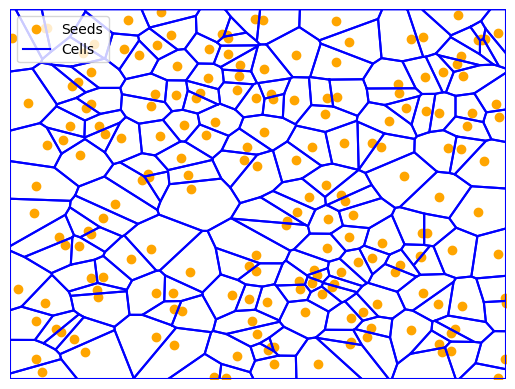

In [38]:
fig, ax = plt.subplots()
ax.scatter(Seeds[0], Seeds[1], color="orange")
for i in range(len(cells) - 1):
    A = np.column_stack(cells[i])
    ax.plot(A[0], A[1], color="blue")
ax.set_xlim(domain_X)
ax.set_ylim(domain_Y)
ax.set_axis_off()
ax.legend(["Seeds", "Cells"])


## Print the Centroids

In [39]:
file = open("output/centroids.txt")
fileString = file.read().split("\n")
file.close()
centroids = []
# for i in range(len(fileString) - 1):
#     point = [float(x) for x in fileString[i].split()]
#     centroids.append(point[1:])

points = [float(x) for x in fileString[0].split()]
for i in range(int(len(points)/3)):
    centroids.append(points[3*i+1:3*(i+1)])

Centroids = np.column_stack(centroids)

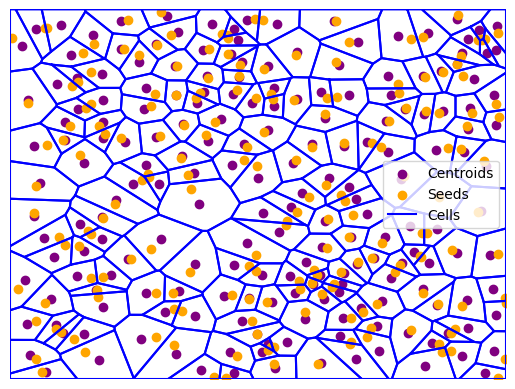

In [40]:
fig, ax = plt.subplots()
ax.scatter(Centroids[0], Centroids[1], color="purple")
ax.scatter(Seeds[0], Seeds[1], color="orange")
for i in range(len(cells) - 1):
    A = np.column_stack(cells[i])
    ax.plot(A[0], A[1], color="blue")
ax.set_xlim(domain_X)
ax.set_ylim(domain_Y)
ax.set_axis_off()
ax.legend(["Centroids", "Seeds", "Cells"])

## Python's Delaunay Triangularization

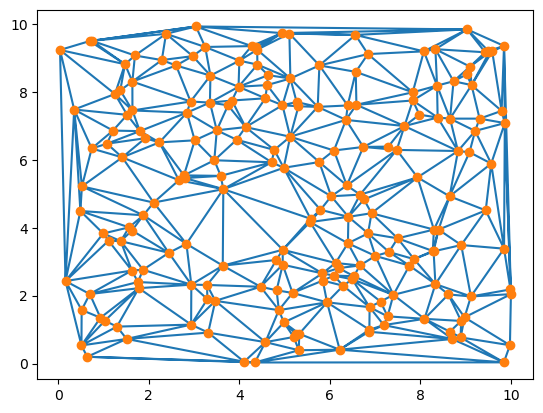

In [41]:
seeds = np.array(seeds)
tri = Delaunay(seeds)
plt.triplot(seeds[:,0], seeds[:,1], tri.simplices, "-o")

plt.show()

## Animate LLoyd's Algo

In [42]:
from matplotlib import rc
rc('animation', html='jshtml')

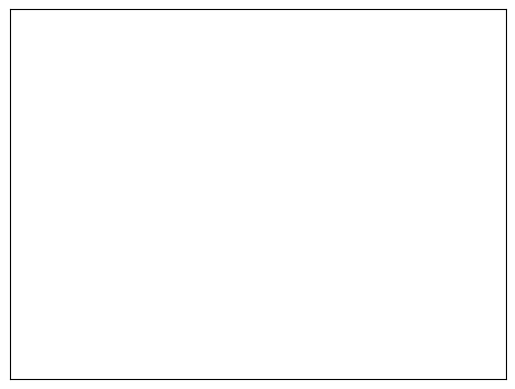

In [43]:
iterations = 30
fig, ax = plt.subplots()

ims = []
for i in range(iterations + 1):
    filename = f"output/lloyd/cellset{i}.gnu"
    file = open(filename)
    fileString = file.read().split("\n")
    file.close()
    cells = []
    vertices = []
    for j in range(len(fileString) - 1):
        vertex = [float(x) for x in fileString[j].split()]
        if vertex == []:
            cells.append(vertices)
            vertices = []
        else:
            vertices.append(vertex)

    ax.set_xticks([])
    ax.set_yticks([])

    frame_artists = []

    # FIX: plot ALL cells, not cells[i]
    for cell in cells:
        A = np.column_stack(cell)
        artist, = ax.plot(A[0], A[1], color="blue")
        frame_artists.append(artist)

    ims.append(frame_artists)
    
ani = animation.ArtistAnimation(fig, ims, blit=True)

In [44]:
ani.save("unnamed_2d_animation.gif", writer=animation.PillowWriter(fps=10))

## The Final iteration of Lloyd's Algo

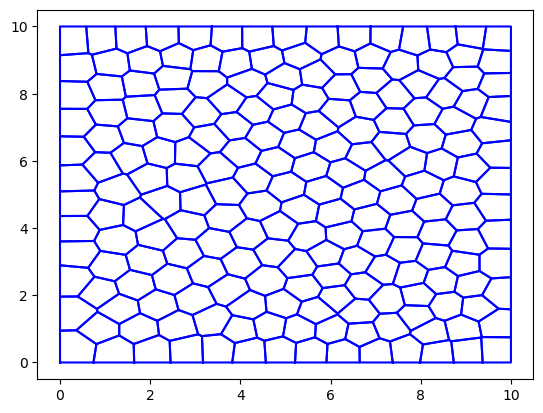

In [45]:
fig, ax = plt.subplots()
for cell in cells:
    A = np.column_stack(cell)
    ax.plot(A[0], A[1], color="blue")